## Agentic AI for Reranking: Preliminary Investigation

This notebook explores using a LangGraph ReAct agent as a **semantic reranker** for cross-language repository similarity.

Author: Boon Heng Chew <<s2831745@sms.ed.ac.uk>>

> Link to **Research Question:** Can an agentic workflow reasoning over inspect4all’s structured JSON metadata match or surpass embedding-based cosine similarity for similarity ranking?

This notebook implements the **agentic reranking pipeline** using:
- `LangGraph` -- ReAct-style agent graph (Thought -> Action -> Observation loop)
- `OpenAI GPT-5` -- LLM backbone
- Structured repository metadata (software_type, key_functions, dependencies) as input

#### Experiment Agentic Workflow
- Load repository metadata for a query repo and N candidate repos
- Present the agent with the query and candidate IDs
- The agent uses ReAct reasoning to:
  1. Inspect the query repository metadata
  2. For each candidate: inspect metadata, compare dependencies, reason about functional similarity
  3. Assign a similarity score (0.0-1.0) with explicit reasoning via `score_candidate`
  4. Validate each score via `validate_score` (CRAG-style confidence gate + truthfulness check)
  5. On validation failure: retry with Reflexion feedback until pass or retries exhausted
  6. Call `finish_ranking` when all candidates are validated
- Compare the agent-produced ranking against ground-truth labels

In [1]:
from platform import python_version
print(f"Python environment: {python_version()}")

Python environment: 3.12.11


#### 1. Setup & Configuration

In [2]:
import json
import os
from pathlib import Path
from typing import Annotated, Any, TypedDict

from dotenv import load_dotenv

load_dotenv()

api_key = os.getenv('OPENAI_API_KEY')
if not api_key:
    raise EnvironmentError(
        'OPENAI_API_KEY not found. Create a .env file in this directory with:\n'
        'OPENAI_API_KEY=sk-...'
    )
print('[OK] OPENAI_API_KEY loaded')

[OK] OPENAI_API_KEY loaded


In [3]:
# LLM configuration
LLM_MODEL = "gpt-5.4"
REASONING_EFFORT = "low"

# Workflow configuration
REPO_DATA_PATH = Path('data/sample_repos.json')
""" Structured repository metadata (query + candidates) """

MAX_RERANK_STEPS = 20
""" Hard step cap per agent invocation """

MAX_RETRY_RERANK = 2
""" Max Reflexion retries per candidate before finalising as unvalidated """

VALIDATION_CONFIDENCE_THRESHOLD = 0.7
""" Minimum confidence for validate_score to pass (CRAG-style gate) """

print(f'Input:         {REPO_DATA_PATH}')
print(f'Model:         {LLM_MODEL}')
print(f'Max steps:     {MAX_RERANK_STEPS}')
print(f'Max retry:     {MAX_RETRY_RERANK}')
print(f'Val threshold: {VALIDATION_CONFIDENCE_THRESHOLD}')

Input:         data/sample_repos.json
Model:         gpt-5.4
Max steps:     20
Max retry:     2
Val threshold: 0.7


#### 2. Load Repository Metadata

In [4]:
def load_repos(path: Path) -> tuple[dict, list[dict], dict]:
    """Load query repo, candidate repos, and ground truth from JSON."""
    with path.open(encoding='utf-8') as f:
        data = json.load(f)
    return data['query'], data['candidates'], data['ground_truth']


query_repo, candidate_repos, ground_truth = load_repos(REPO_DATA_PATH)
gt_labels = ground_truth['labels']

query_lang = query_repo.get('metadata', {}).get('language') or list(query_repo.get('languages', {}).keys())[0]
print(f'Query repo:      {query_repo["repo_id"]} ({query_lang}, {query_repo["software_type"]})')
print(f'Candidates:      {len(candidate_repos)}')
print()
print('Candidates (ground truth):')
for c in candidate_repos:
    label   = gt_labels.get(c['repo_id'], '?')
    c_lang  = c.get('metadata', {}).get('language') or list(c.get('languages', {}).keys())[0]
    print(f'  {c["repo_id"]:45s}  {label}  ({c_lang}, {c["software_type"]})')

Query repo:      auth0/java-jwt (Java, library)
Candidates:      5

Candidates (ground truth):
  jpadilla/pyjwt                                 HIGH  (Python, library)
  mpdavis/python-jose                            HIGH  (Python, library)
  connect2id/nimbus-jose-jwt                     HIGH  (Java, library)
  spring-projects/spring-security                MEDIUM  (Java, framework)
  psf/requests                                   LOW  (Python, library)


In [5]:
meta = query_repo.get('metadata', {})
deps = query_repo.get('dependencies', [])
print('Query repo metadata:')
print(f'  Name:         {meta.get("name", query_repo["repo_id"])}')
print(f'  Languages:    {query_repo.get("languages", {})}')
print(f'  Type:         {query_repo["software_type"]}')
print(f'  Description:  {meta.get("description", "n/a")[:100]}')
print(f'  Doc records:  {len(query_repo.get("doc_records", []))} methods/functions')
print(f'  Dependencies: {[d["name"] for d in deps]}')
print(f'  README:       {len(query_repo.get("readme", {}).get("text", ""))} chars')

Query repo metadata:
  Name:         java-jwt
  Languages:    {'Java': 52}
  Type:         library
  Description:  Java implementation of JSON Web Tokens (JWT) following RFC 7519.
  Doc records:  5 methods/functions
  Dependencies: ['jackson-databind', 'commons-codec', 'junit', 'bcprov-jdk15on']
  README:       658 chars


## 3. LangGraph ReAct Reranker Agent

The agent follows the **ReAct pattern** (Yao et al., 2022) -- a Thought -> Action -> Observation loop:

```
START -> agent (Thought) -> tools (Action+Observation) -> agent -> ... -> END

  Step 1: inspect_repo(query_id)             -- understand what the query repo does

  Step 2: inspect_repo(candidate_id)         -- understand each candidate
          compare_dependencies(candidate_id) -- structural overlap signal

  Step 3: score_candidate(candidate_id, score, reasoning)
          -- assigns 0.0-1.0 similarity score with explicit 2-3 sentence rationale

  Step 4: validate_score(candidate_id)
          -- Dim 1: LLM-as-judge checks score-reasoning consistency  (CRAG)
          -- Dim 2: truthfulness cross-ref against _repo_registry
          -- PASS -> agent_scored
          -- FAIL + retries remain -> retry_recommended=True + retry_feedback (Reflexion)
          -- FAIL + exhausted     -> agent_scored_unvalidated

  Step 5: finish_ranking(summary)            -- submit final ranking
```

Three quality mechanisms are layered on top of the basic ReAct loop:

- **CRAG-style confidence gate** -- LLM-as-judge checks whether the numeric score is
  consistent with the stated reasoning before finalising
- **Reflexion-style retry** -- verbal feedback from validate_score is passed back to
  score_candidate when consistency is low
- **Truthfulness cross-reference** -- entity names in reasoning cross-checked against
  _repo_registry; unverified package-like names penalise confidence

### Tools registered

| Tool | Purpose | Theory |
|------|---------|--------|
| `inspect_repo` | Full metadata for any repo (query or candidate) - software_type, functions, dependencies | ReAct |
| `compare_dependencies` | Dep overlap between query and a candidate (shared count, Jaccard similarity) | ReAct |
| `score_candidate` | Record similarity score + reasoning; accepts Reflexion feedback on retry | Reflexion |
| `validate_score` | LLM-as-judge consistency check + truthfulness cross-ref; Reflexion gate | CRAG, Reflexion |
| `finish_ranking` | Signal reranking complete (guards against premature exit) | -- |

In [6]:
import json
import re

from langchain_core.messages import AnyMessage, HumanMessage
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode


class RerankState(TypedDict):
    messages:      Annotated[list[AnyMessage], add_messages]
    query_repo_id: str
    candidate_ids: list[str]
    step_count:    int
    finished:      bool


# --- Registries ---
_repo_registry:  dict[str, dict] = {}   # ground-truth metadata (read-only)
_score_registry: dict[str, dict] = {}   # scores + provenance written by score_candidate
_retry_registry: dict[str, int]  = {}   # Reflexion retry counter per candidate
_query_id:       str              = ''
_candidate_ids:  list[str]        = []

# Validation threshold -- overridden in run cell from VALIDATION_CONFIDENCE_THRESHOLD config
_VALIDATION_CONFIDENCE_THRESHOLD: float = 0.7

# LLM judge instance (used by validate_score; initialised when tools cell runs)
_llm_judge: ChatOpenAI | None = None


def _dep_names(repo: dict) -> set[str]:
    """Extract lowercase dependency names from a repo dict.

    Handles both object format (inspect4all): [{"name": "junit", ...}]
    and legacy flat string format: ["junit", ...]
    """
    raw = repo.get('dependencies', [])
    names: set[str] = set()
    for d in raw:
        if isinstance(d, dict):
            names.add(d.get('name', '').lower())
        elif isinstance(d, str):
            names.add(d.lower())
    return names


# --- Tools ---

@tool
def inspect_repo(repo_id: str) -> dict:
    """Retrieve the full metadata for a repository: software_type, description,
    doc_records (qualified method names + docstrings), dependencies, languages.

    Use this for both the query repository and each candidate before scoring.

    Args:
        repo_id: Repository ID (e.g. 'auth0/java-jwt').
    """
    repo = _repo_registry.get(repo_id)
    if repo is None:
        return {'error': f'repo_id "{repo_id}" not found. Available: {list(_repo_registry.keys())}'}
    return repo


@tool
def compare_dependencies(repo_id: str) -> dict:
    """Compare the dependency list of a candidate against the query repository.

    Returns shared dependencies, query-only, candidate-only, and Jaccard similarity.
    High dependency overlap is a strong structural signal of functional similarity.

    Args:
        repo_id: Candidate repository ID to compare against the query.
    """
    query     = _repo_registry.get(_query_id)
    candidate = _repo_registry.get(repo_id)
    if query is None:
        return {'error': f'Query repo "{_query_id}" not found in registry'}
    if candidate is None:
        return {'error': f'Candidate repo "{repo_id}" not found in registry'}
    q_deps = _dep_names(query)
    c_deps = _dep_names(candidate)
    shared = q_deps & c_deps
    union  = q_deps | c_deps
    return {
        'query_repo':         _query_id,
        'candidate_repo':     repo_id,
        'shared':             sorted(shared),
        'shared_count':       len(shared),
        'query_only':         sorted(q_deps - c_deps),
        'candidate_only':     sorted(c_deps - q_deps),
        'jaccard_similarity': round(len(shared) / len(union), 3) if union else 0.0,
    }


@tool
def score_candidate(repo_id: str, score: float, reasoning: str, feedback: str = '') -> dict:
    """Assign a similarity score to a candidate repository with explicit reasoning.

    Score range: 0.0 (completely different) to 1.0 (functionally identical).
    After scoring, always call validate_score(repo_id) to validate and finalise.

    On validation failure with retry_recommended=True, re-call score_candidate with
    the retry_feedback value in the feedback argument, then call validate_score again
    (Reflexion retry).

    Args:
        repo_id:   Candidate repository ID to score.
        score:     Similarity score between 0.0 and 1.0.
        reasoning: 2-3 sentence explanation covering purpose overlap, language/type match,
                   dependency overlap, and any disqualifying differences.
        feedback:  Optional. Reflexion feedback string from a failed validate_score call.
                   Include this when retrying after validation failure.
    """
    if repo_id not in _repo_registry:
        return {'error': f'repo_id "{repo_id}" not found in registry'}
    # Idempotency guard: skip if already in final provenance
    cur_prov = _score_registry.get(repo_id, {}).get('provenance', '')
    if cur_prov in ('agent_scored', 'agent_scored_unvalidated'):
        return {
            'info':      f'SKIP: "{repo_id}" already finalised ({cur_prov}). Do not re-score.',
            'score':     _score_registry[repo_id]['score'],
            'provenance': cur_prov,
        }
    score = max(0.0, min(1.0, float(score)))
    _score_registry[repo_id] = {
        'repo_id':   repo_id,
        'score':     score,
        'reasoning': reasoning,
        'provenance': 'agent_pending',
    }
    unfinished = [
        c for c in _candidate_ids
        if _score_registry.get(c, {}).get('provenance', '') not in ('agent_scored', 'agent_scored_unvalidated')
    ]
    return {
        'repo_id':           repo_id,
        'score':             score,
        'reasoning_preview': reasoning[:120],
        'provenance':        'agent_pending',
        'info':              f'Score recorded. Now call validate_score("{repo_id}") to validate and finalise.',
        'unfinished_count':  len(unfinished),
        'unfinished_ids':    unfinished,
    }


@tool
def validate_score(repo_id: str) -> dict:
    """Validate the scoring of a candidate.

    Two validation dimensions:
      Dim 1: LLM-as-judge consistency -- checks whether the numeric score is
             consistent with the stated reasoning (CRAG-style confidence gate).
      Dim 2: Truthfulness cross-reference -- checks package-like entity names
             in the reasoning against _repo_registry.

    Outcome:
      confidence >= threshold -> provenance set to agent_scored
      confidence < threshold + retries remain -> retry_recommended=True + retry_feedback
      confidence < threshold + retries exhausted -> agent_scored_unvalidated

    Args:
        repo_id: Candidate repository ID to validate.
    """
    entry = _score_registry.get(repo_id)
    if entry is None:
        return {'error': f'No score found for "{repo_id}". Call score_candidate first.'}

    # Idempotency guard
    cur_prov = entry.get('provenance', '')
    if cur_prov in ('agent_scored', 'agent_scored_unvalidated'):
        return {
            'info':      f'SKIP: "{repo_id}" already finalised ({cur_prov}).',
            'repo_id':   repo_id,
            'provenance': cur_prov,
        }

    score     = entry['score']
    reasoning = entry['reasoning']

    # --- Dimension 1: LLM-as-judge consistency ---
    judge_prompt = (
        f'Score consistency check.\n'
        f'Query repo:  {_query_id}\n'
        f'Candidate:   {repo_id}\n'
        f'Score:       {score:.2f}  (0.0=completely different, 1.0=functionally identical)\n'
        f'Reasoning:   {reasoning}\n\n'
        f'Is the numeric score consistent with the reasoning?\n'
        f'  score >= 0.7 -> reasoning must show strong purpose/domain overlap\n'
        f'  score 0.3-0.7 -> reasoning should show partial overlap\n'
        f'  score < 0.3 -> reasoning should show low/no overlap\n\n'
        f'Reply with JSON only: {{"consistency": 0.0-1.0, "explanation": "one sentence"}}'
    )
    consistency       = 0.5
    judge_explanation = 'judge call failed'
    try:
        resp = _llm_judge.invoke(judge_prompt)
        raw  = resp.content.strip()
        m    = re.search(r'\{[^}]+\}', raw, re.DOTALL)
        if m:
            parsed            = json.loads(m.group())
            consistency       = float(parsed.get('consistency', 0.5))
            judge_explanation = str(parsed.get('explanation', ''))
    except Exception:
        pass
    confidence = consistency

    # --- Dimension 2: Truthfulness cross-reference ---
    known: set[str] = set()
    for r in _repo_registry.values():
        known.add(r.get('repo_id', '').lower())
        known.add(r.get('metadata', {}).get('name', '').lower())
        known.update(_dep_names(r))
        known.update(
            rec.get('qualified_name', '').lower()
            for rec in r.get('doc_records', [])
        )

    # Extract package-like tokens (e.g. 'com.auth0.jwt', 'nimbus-jose-jwt')
    suspicious   = re.findall(r'\b[a-z][a-z0-9_-]*(?:\.[a-z][a-z0-9_-]+)+\b', reasoning.lower())
    hallucinated = [s for s in suspicious if s not in known]
    penalty      = min(len(hallucinated) * 0.1, 0.3)
    confidence   = max(0.0, confidence - penalty)

    retries_used = _retry_registry.get(repo_id, 0)

    # --- PASS ---
    if confidence >= _VALIDATION_CONFIDENCE_THRESHOLD:
        _score_registry[repo_id]['provenance'] = 'agent_scored'
        return {
            'repo_id':               repo_id,
            'score':                 score,
            'valid':                 True,
            'confidence':            round(confidence, 3),
            'consistency':           round(consistency, 3),
            'judge_explanation':     judge_explanation,
            'hallucinated_entities': hallucinated,
            'provenance':            'agent_scored',
        }

    # --- FAIL: retries remain ---
    if retries_used < MAX_RETRY_RERANK:
        _retry_registry[repo_id] = retries_used + 1
        issues = []
        if consistency < _VALIDATION_CONFIDENCE_THRESHOLD:
            issues.append(
                f'score {score:.2f} may be inconsistent with reasoning '
                f'(judge consistency={consistency:.2f})'
            )
        if hallucinated:
            issues.append(f'possibly hallucinated entity references: {hallucinated}')
        retry_feedback = (
            f'Validation failed for "{repo_id}": {"; ".join(issues)}. '
            f'Retry {retries_used + 1}/{MAX_RETRY_RERANK}: '
            f'revise score and/or reasoning to address these issues.'
        )
        return {
            'repo_id':           repo_id,
            'valid':             False,
            'confidence':        round(confidence, 3),
            'retry_recommended': True,
            'retry_feedback':    retry_feedback,
            'retries_remaining': MAX_RETRY_RERANK - retries_used - 1,
        }

    # --- FAIL: retries exhausted ---
    _score_registry[repo_id]['provenance'] = 'agent_scored_unvalidated'
    return {
        'repo_id':           repo_id,
        'score':             score,
        'valid':             False,
        'confidence':        round(confidence, 3),
        'retry_recommended': False,
        'provenance':        'agent_scored_unvalidated',
        'info':              'Max retries exhausted. Score finalised as agent_scored_unvalidated.',
    }


@tool
def finish_ranking(summary: str) -> str:
    """Signal that reranking is complete. Call only after all candidates are validated
    (provenance is agent_scored or agent_scored_unvalidated for every candidate).

    Args:
        summary: Brief description of the ranking rationale.
    """
    unfinished = [
        cid for cid in _candidate_ids
        if _score_registry.get(cid, {}).get('provenance', '') not in ('agent_scored', 'agent_scored_unvalidated')
    ]
    if unfinished:
        return (
            f'NOT COMPLETE: {len(unfinished)} candidates not yet validated: {unfinished}. '
            f'Score and validate them before calling finish_ranking.'
        )
    return f'RERANKING COMPLETE: {summary}'


# LLM judge instance -- used inside validate_score for Dim 1 consistency check
_llm_judge = ChatOpenAI(model=LLM_MODEL, use_responses_api=True, temperature=0)

tools = [inspect_repo, compare_dependencies, score_candidate, validate_score, finish_ranking]
print(f'[OK] {len(tools)} tools registered: {[t.name for t in tools]}')
print('  inspect_repo:         full metadata lookup (query or candidate)')
print('  compare_dependencies: structural overlap signal (Jaccard)')
print('  score_candidate:      record score + reasoning (Reflexion feedback supported)')
print('  validate_score:       LLM-as-judge consistency + truthfulness cross-ref')
print('  finish_ranking:       signal completion (guards unvalidated candidates)')


[OK] 5 tools registered: ['inspect_repo', 'compare_dependencies', 'score_candidate', 'validate_score', 'finish_ranking']
  inspect_repo:         full metadata lookup (query or candidate)
  compare_dependencies: structural overlap signal (Jaccard)
  score_candidate:      record score + reasoning (Reflexion feedback supported)
  validate_score:       LLM-as-judge consistency + truthfulness cross-ref
  finish_ranking:       signal completion (guards unvalidated candidates)


In [7]:
llm = ChatOpenAI(model=LLM_MODEL, reasoning_effort=REASONING_EFFORT, use_responses_api=True, temperature=0)
llm_with_tools = llm.bind_tools(tools)


def agent_node(state: RerankState) -> dict:
    """Agent reasoning node -- LLM decides the next action."""
    response = llm_with_tools.invoke(state['messages'])
    return {'messages': [response]}


def should_continue(state: RerankState) -> str:
    """Routing: continue ReAct loop or terminate.

    Three exit conditions (checked in priority order):
      1. Hard step cap  -- MAX_RERANK_STEPS reached (safety)
      2. Semantic exit  -- all candidates in final provenance (agent_scored or agent_scored_unvalidated)
      3. Model exit     -- model called finish_ranking or emitted no tool calls
    """
    # 1. Hard safety cap
    if state['step_count'] >= MAX_RERANK_STEPS:
        print(f'  [SAFETY] Max steps ({MAX_RERANK_STEPS}) reached -- terminating.')
        return END

    # 2. Semantic exit: all candidates in final provenance
    if state['candidate_ids'] and all(
        _score_registry.get(cid, {}).get('provenance', '') in ('agent_scored', 'agent_scored_unvalidated')
        for cid in state['candidate_ids']
    ):
        print(f'  [AUTO-EXIT] All {len(state["candidate_ids"])} candidates validated -- terminating.')
        return END

    # 3. Model-driven exit
    last_message = state['messages'][-1]
    tool_calls   = getattr(last_message, 'tool_calls', [])
    if not tool_calls:
        return END
    for tc in tool_calls:
        if tc['name'] == 'finish_ranking':
            return END
    return 'tools'


def increment_step(state: RerankState) -> dict:
    """Increment the step counter after each tool execution."""
    new_count = state['step_count'] + 1
    print(f'  Step {new_count}: tool executed')
    return {'step_count': new_count}


tool_node = ToolNode(tools)
builder = StateGraph(RerankState)
builder.add_node('agent', agent_node)
builder.add_node('tools', tool_node)
builder.add_node('step_counter', increment_step)
builder.add_edge(START, 'agent')
builder.add_conditional_edges('agent', should_continue, {'tools': 'tools', END: END})
builder.add_edge('tools', 'step_counter')
builder.add_edge('step_counter', 'agent')
graph = builder.compile()

print('[OK] LangGraph agent compiled')
print('  Graph: START -> agent -> [tools -> step_counter -> agent]* -> END')
print('  Exit:  step_cap | all_validated | finish_ranking | no_tool_calls')

[OK] LangGraph agent compiled
  Graph: START -> agent -> [tools -> step_counter -> agent]* -> END
  Exit:  step_cap | all_validated | finish_ranking | no_tool_calls


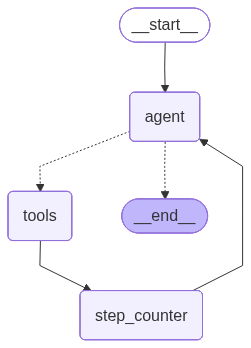

In [8]:
try:
    from IPython.display import Image, display
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f'Graph visualisation unavailable: {e}')

## 4. Run the Reranker Agent

In [9]:
def _repo_lang(repo: dict) -> str:
    """Extract primary language from a repo dict (inspect4all schema)."""
    lang = repo.get('metadata', {}).get('language')
    if not lang:
        langs = repo.get('languages', {})
        lang  = next(iter(langs), 'unknown') if langs else 'unknown'
    return lang


def build_rerank_prompt(query: dict, candidates: list[dict]) -> str:
    """Build the initial agent prompt for the reranking task."""
    candidate_lines = '\n'.join(
        f'  {i+1}. {c["repo_id"]}  ({_repo_lang(c)}, {c["software_type"]})'
        for i, c in enumerate(candidates)
    )
    return (
        f'You are a repository similarity reranker for cross-language code search.\n\n'
        f'Query repository: {query["repo_id"]}\n\n'
        f'Your task (follow steps in order):\n'
        f'  1. Call inspect_repo("{query["repo_id"]}") to understand what the query repo does.\n'
        f'  2. For each candidate, call inspect_repo(candidate_id) and '
        f'compare_dependencies(candidate_id) to gather evidence.\n'
        f'  3. Call score_candidate(candidate_id, score, reasoning) for each candidate.\n'
        f'     Score: 0.0 = completely different, 1.0 = functionally identical.\n'
        f'     Reasoning: 2-3 sentences covering purpose overlap, software type,\n'
        f'     language/port relationship, and dependency overlap.\n'
        f'  4. Call validate_score(candidate_id) for each scored candidate.\n'
        f'     If validate_score returns retry_recommended=True:\n'
        f'       -> Call score_candidate(candidate_id, revised_score, revised_reasoning,\n'
        f'                               feedback=retry_feedback)  (Reflexion retry)\n'
        f'       -> Then call validate_score(candidate_id) again.\n'
        f'  5. Call finish_ranking with a brief summary once all candidates are validated.\n\n'
        f'Scoring guidance:\n'
        f'  - Different language does NOT lower the score if the repos implement the same\n'
        f'    spec/protocol -- treat this as a cross-language port (still high similarity).\n'
        f'  - software_type mismatch (library vs framework) DOES lower the score.\n'
        f'  - Shared dependencies are a strong structural signal of functional overlap.\n'
        f'  - Do NOT re-score a candidate already in agent_scored or agent_scored_unvalidated.\n\n'
        f'Candidates to rank:\n{candidate_lines}\n\n'
        f'Start by inspecting the query repository.'
    )


initial_prompt = build_rerank_prompt(query_repo, candidate_repos)
print(initial_prompt)


You are a repository similarity reranker for cross-language code search.

Query repository: auth0/java-jwt

Your task (follow steps in order):
  1. Call inspect_repo("auth0/java-jwt") to understand what the query repo does.
  2. For each candidate, call inspect_repo(candidate_id) and compare_dependencies(candidate_id) to gather evidence.
  3. Call score_candidate(candidate_id, score, reasoning) for each candidate.
     Score: 0.0 = completely different, 1.0 = functionally identical.
     Reasoning: 2-3 sentences covering purpose overlap, software type,
     language/port relationship, and dependency overlap.
  4. Call validate_score(candidate_id) for each scored candidate.
     If validate_score returns retry_recommended=True:
       -> Call score_candidate(candidate_id, revised_score, revised_reasoning,
                               feedback=retry_feedback)  (Reflexion retry)
       -> Then call validate_score(candidate_id) again.
  5. Call finish_ranking with a brief summary once al

In [10]:
# Initialise registries
_repo_registry.clear()
_score_registry.clear()
_retry_registry.clear()
_repo_registry[query_repo['repo_id']] = query_repo
for c in candidate_repos:
    _repo_registry[c['repo_id']] = c

# Bind config to module-level validation threshold
_VALIDATION_CONFIDENCE_THRESHOLD = VALIDATION_CONFIDENCE_THRESHOLD

# Set module-level context for compare_dependencies
_query_id = query_repo['repo_id']
_candidate_ids[:] = [c['repo_id'] for c in candidate_repos]

print(f'[OK] Repo registry:        {len(_repo_registry)} repos')
print(f'[OK] Score registry:       empty')
print(f'[OK] Retry registry:       empty')
print(f'[OK] Validation threshold: {_VALIDATION_CONFIDENCE_THRESHOLD}')
print(f'[OK] Query ID:             {_query_id}')
print(f'[OK] Candidates:           {_candidate_ids}')

initial_state: RerankState = {
    'messages':      [HumanMessage(content=initial_prompt)],
    'query_repo_id': query_repo['repo_id'],
    'candidate_ids': [c['repo_id'] for c in candidate_repos],
    'step_count':    0,
    'finished':      False,
}

print(f'\nRunning reranker on {len(candidate_repos)} candidates...')
print('-' * 60)
final_state = graph.invoke(initial_state)
print('-' * 60)
print(f'Done. Steps used:   {final_state["step_count"]} / {MAX_RERANK_STEPS}')
print(f'Total messages:     {len(final_state["messages"])}')
print(f'Candidates scored:  {len(_score_registry)} / {len(candidate_repos)}')

# Provenance breakdown
agent_scored             = sum(1 for e in _score_registry.values() if e.get('provenance') == 'agent_scored')
agent_scored_unvalidated = sum(1 for e in _score_registry.values() if e.get('provenance') == 'agent_scored_unvalidated')
print(f'  agent_scored:             {agent_scored}')
print(f'  agent_scored_unvalidated: {agent_scored_unvalidated}')

[OK] Repo registry:        6 repos
[OK] Score registry:       empty
[OK] Retry registry:       empty
[OK] Validation threshold: 0.7
[OK] Query ID:             auth0/java-jwt
[OK] Candidates:           ['jpadilla/pyjwt', 'mpdavis/python-jose', 'connect2id/nimbus-jose-jwt', 'spring-projects/spring-security', 'psf/requests']

Running reranker on 5 candidates...
------------------------------------------------------------
  Step 1: tool executed
  Step 2: tool executed
  Step 3: tool executed
  Step 4: tool executed
  Step 5: tool executed
  Step 6: tool executed
  Step 7: tool executed
  Step 8: tool executed
  [AUTO-EXIT] All 5 candidates validated -- terminating.
------------------------------------------------------------
Done. Steps used:   8 / 20
Total messages:     51
Candidates scored:  5 / 5
  agent_scored:             0
  agent_scored_unvalidated: 5


## 5. Reranking Results

In [11]:
ranked = sorted(_score_registry.values(), key=lambda x: x['score'], reverse=True)

print('Agent Reranking (highest -> lowest similarity):')
print()
print(f'  {"Rank":<5} {"Score":<8} {"GT Label":<10} {"Provenance":<28} {"Repo ID"}')
print(f'  {"-"*5} {"-"*7} {"-"*9} {"-"*27} {"-"*40}')
for rank, entry in enumerate(ranked, 1):
    rid   = entry['repo_id']
    score = entry['score']
    label = gt_labels.get(rid, '?')
    prov  = entry.get('provenance', '?')
    icon  = '[OK]' if prov == 'agent_scored' else '[NOTE]'
    print(f'  {rank:<5} {score:<8.2f} {label:<10} {icon} {prov:<24} {rid}')

print()
print('Reasoning per candidate:')
print()
for entry in ranked:
    rid  = entry['repo_id']
    repo = _repo_registry[rid]
    lang = _repo_lang(repo)
    prov = entry.get('provenance', '?')
    retries = _retry_registry.get(rid, 0)
    retry_str = f'  retries={retries}' if retries > 0 else ''
    print(f'  [{entry["score"]:.2f}] {rid}  ({lang}, {repo["software_type"]})  [{prov}{retry_str}]')
    print(f'         {entry["reasoning"]}')
    print()


Agent Reranking (highest -> lowest similarity):

  Rank  Score    GT Label   Provenance                   Repo ID
  ----- ------- --------- --------------------------- ----------------------------------------
  1     0.90     HIGH       [NOTE] agent_scored_unvalidated jpadilla/pyjwt
  2     0.80     HIGH       [NOTE] agent_scored_unvalidated connect2id/nimbus-jose-jwt
  3     0.72     HIGH       [NOTE] agent_scored_unvalidated mpdavis/python-jose
  4     0.18     MEDIUM     [NOTE] agent_scored_unvalidated spring-projects/spring-security
  5     0.00     LOW        [NOTE] agent_scored_unvalidated psf/requests

Reasoning per candidate:

  [0.90] jpadilla/pyjwt  (Python, library)  [agent_scored_unvalidated  retries=2]
         PyJWT is a Python library dedicated to the same core job as auth0/java-jwt: generating, signing, decoding, and verifying JWTs under RFC 7519. It is best understood as a cross-language counterpart with matching library type and highly overlapping API-level purpose, w

In [12]:
label_order = {'HIGH': 0, 'MEDIUM': 1, 'LOW': 2}
gt_ranked   = sorted(
    candidate_repos,
    key=lambda c: label_order.get(gt_labels.get(c['repo_id'], 'LOW'), 3)
)

print('Agent ranking vs Ground Truth:')
print()
print(f'  {"Repo ID":<45} {"Agent Rank":<12} {"GT Label"}')
print(f'  {"-"*44} {"-"*11} {"-"*8}')

agent_rank_map = {entry['repo_id']: i+1 for i, entry in enumerate(ranked)}
for c in gt_ranked:
    rid        = c['repo_id']
    agent_rank = agent_rank_map.get(rid, 'N/A')
    label      = gt_labels.get(rid, '?')
    match = '[OK]' if isinstance(agent_rank, int) and (
        (label == 'HIGH'   and agent_rank <= 3) or
        (label == 'MEDIUM' and agent_rank == 4) or
        (label == 'LOW'    and agent_rank == 5)
    ) else '[NOTE]'
    print(f'  {rid:<45} {str(agent_rank):<12} {label:<8} {match}')

Agent ranking vs Ground Truth:

  Repo ID                                       Agent Rank   GT Label
  -------------------------------------------- ----------- --------
  jpadilla/pyjwt                                1            HIGH     [OK]
  mpdavis/python-jose                           3            HIGH     [OK]
  connect2id/nimbus-jose-jwt                    2            HIGH     [OK]
  spring-projects/spring-security               4            MEDIUM   [OK]
  psf/requests                                  5            LOW      [OK]


In [13]:
print('=' * 70)
print('AGENT CONVERSATION TRACE')
print('=' * 70)

for i, msg in enumerate(final_state['messages']):
    msg_type = type(msg).__name__
    if msg_type == 'HumanMessage':
        print(f'\n[{i}] HumanMessage:')
        print(f'  {str(msg.content)[:200]}...')
    elif msg_type == 'AIMessage':
        tool_calls = getattr(msg, 'tool_calls', [])
        print(f'\n[{i}] AIMessage ({len(tool_calls)} tool calls):')
        for tc in tool_calls:
            args_preview = str(tc.get('args', {}))[:120]
            print(f'  -> {tc["name"]}({args_preview})')
    elif msg_type == 'ToolMessage':
        tool_name = getattr(msg, 'name', '?')
        content_preview = str(msg.content)[:200]
        print(f'\n[{i}] ToolMessage [{tool_name}]:')
        print(f'  {content_preview}')

AGENT CONVERSATION TRACE

[0] HumanMessage:
  You are a repository similarity reranker for cross-language code search.

Query repository: auth0/java-jwt

Your task (follow steps in order):
  1. Call inspect_repo("auth0/java-jwt") to understand wh...

[1] AIMessage (1 tool calls):
  -> inspect_repo({'repo_id': 'auth0/java-jwt'})

[2] ToolMessage [inspect_repo]:
  {"repo_id": "auth0/java-jwt", "metadata": {"name": "java-jwt", "full_name": "auth0/java-jwt", "description": "Java implementation of JSON Web Tokens (JWT) following RFC 7519.", "language": "Java"}, "l

[3] AIMessage (10 tool calls):
  -> inspect_repo({'repo_id': 'jpadilla/pyjwt'})
  -> compare_dependencies({'repo_id': 'jpadilla/pyjwt'})
  -> inspect_repo({'repo_id': 'mpdavis/python-jose'})
  -> compare_dependencies({'repo_id': 'mpdavis/python-jose'})
  -> inspect_repo({'repo_id': 'connect2id/nimbus-jose-jwt'})
  -> compare_dependencies({'repo_id': 'connect2id/nimbus-jose-jwt'})
  -> inspect_repo({'repo_id': 'spring-projects/spr

## 6. Save Output

In [14]:
output = {
    'query_repo_id': query_repo['repo_id'],
    'ranked':        ranked,
    'ground_truth':  gt_labels,
    'steps_used':    final_state['step_count'],
    'retries_used':  dict(_retry_registry),
}

output_path = Path('output_reranked.json')
with output_path.open('w', encoding='utf-8') as f:
    json.dump(output, f, indent=2, ensure_ascii=False)

print(f'[OK] Saved reranking output -> {output_path}')
print(f'     {len(ranked)} candidates ranked, {final_state["step_count"]} steps used')
if _retry_registry:
    print(f'     Reflexion retries: {dict(_retry_registry)}')

[OK] Saved reranking output -> output_reranked.json
     5 candidates ranked, 8 steps used
     Reflexion retries: {'spring-projects/spring-security': 2, 'psf/requests': 2, 'mpdavis/python-jose': 2, 'jpadilla/pyjwt': 2, 'connect2id/nimbus-jose-jwt': 2}


## 7. Observations & Next Steps

### What this experiment demonstrates

| Aspect | Result |
|--------|--------|
| **Mixed-signal reasoning** | Agent combines code, docstring, dependency, software_type, and language signals into a single judgment |
| **Cross-language port identification** | Language difference is treated as a port signal, not a penalty (PyJWT = Python port of RFC 7519) |
| **Structural signals** | `compare_dependencies` Jaccard + `software_type` provide signals embeddings cannot capture |
| **Interpretability** | Each score has an auditable reasoning trace -- embeddings have no equivalent |
| **CRAG confidence gate** | LLM-as-judge validates score-reasoning consistency before finalising |
| **Truthfulness check** | Package-like entity names in reasoning cross-referenced against `_repo_registry` |
| **Reflexion retry** | Failed validations trigger score revision with verbal feedback |
| **Provenance chain** | `agent_pending` -> `agent_scored` / `agent_scored_unvalidated` |

### Signal Decomposition

| Signal | In embedding? | Agent contribution |
|--------|---------------|--------------------|
| README text | Yes (README embedding) | Re-reasons over content |
| Code + docstrings | Yes (code + doc embedding) | Re-reasons over content |
| `software_type` | No | Explicit categorical judgment (library vs framework) |
| `dependencies` | No | Jaccard overlap + semantic meaning of shared deps |
| `language` | Partial | Cross-language port identification (same spec, different language) |
| Cross-signal synthesis | No | Core value -- combines all signals into score + rationale |

Language difference is a useful signal, not a disqualifier. The agent identifies
cross-language ports (PyJWT and java-jwt both implement RFC 7519 -- high similarity)
and distinguishes them from same-language frameworks that only partially overlap
(spring-security includes JWT support but is primarily an auth framework -- medium).

### Quality Mechanisms vs Enrichment Pipeline

| Mechanism | Enrichment (docstring) | Reranker (score) |
|-----------|----------------------|-----------------|
| CRAG confidence gate (P67) | LLM-as-judge validates generated docstring helpfulness | LLM-as-judge validates score-reasoning consistency |
| Reflexion retry (P68) | Retry `enrich_docstring` with verbal feedback | Retry `score_candidate` with verbal feedback |
| Truthfulness cross-ref (P41) | `{@link}` / class names vs `_method_registry` | Package-like tokens in reasoning vs `_repo_registry` |
| Provenance chain | `missing` -> `agent_backfill` -> `agent_enriched` | `agent_pending` -> `agent_scored` |

### Agent Reranker vs Embedding Baseline

The agentic reranker is the second stage of a **hybrid two-stage pipeline**:

```
Stage 1 (Embedding retrieval):  cosine similarity -> top-k candidates  (fast, recall-focused)
Stage 2 (Agentic reranking):    LLM reasons over top-k metadata       (slow, precision-focused)
```

Embeddings collapse all signals into a fixed-length vector, losing the ability to reason
about *why* repositories are similar. The agent distinguishes a cross-language port
(high similarity) from a same-language framework with partial JWT overlap (medium) --
a judgment that cosine distance alone cannot reliably make.
